Found 7356 images belonging to 102 classes.
Found 1788 images belonging to 102 classes.
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 15s 0us/step
Epoch 1/5


C:\Users\ASUS\anaconda3\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


230/230 ━━━━━━━━━━━━━━━━━━━━ 209s 893ms/step - accuracy: 0.7545 - loss: 1.0971 - val_accuracy: 0.8730 - val_loss: 0.4538
Epoch 2/5
230/230 ━━━━━━━━━━━━━━━━━━━━ 200s 870ms/step - accuracy: 0.9483 - loss: 0.1941 - val_accuracy: 0.8977 - val_loss: 0.3836
Epoch 3/5
230/230 ━━━━━━━━━━━━━━━━━━━━ 202s 879ms/step - accuracy: 0.9787 - loss: 0.0853 - val_accuracy: 0.8870 - val_loss: 0.3841
Epoch 4/5
230/230 ━━━━━━━━━━━━━━━━━━━━ 215s 934ms/step - accuracy: 0.9890 - loss: 0.0458 - val_accuracy: 0.9060 - val_loss: 0.3333
Epoch 5/5
230/230 ━━━━━━━━━━━━━━━━━━━━ 198s 860ms/step - accuracy: 0.9940 - loss: 0.0273 - val_accuracy: 0.9116 - val_loss: 0.3140
56/56 ━━━━━━━━━━━━━━━━━━━━ 36s 641ms/step - accuracy: 0.9116 - loss: 0.3140
Validation Loss: 0.313977986574173
Validation Accuracy: 0.9116331338882446


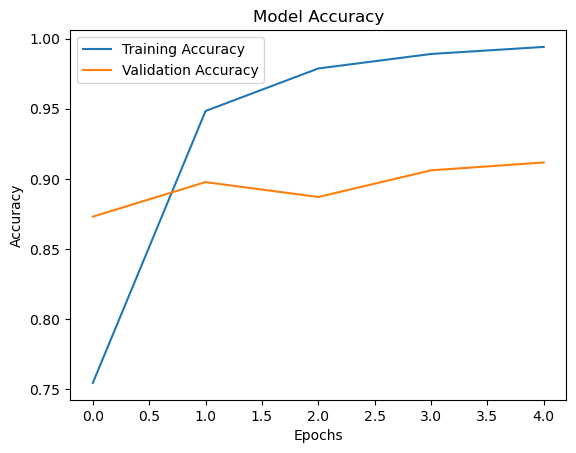

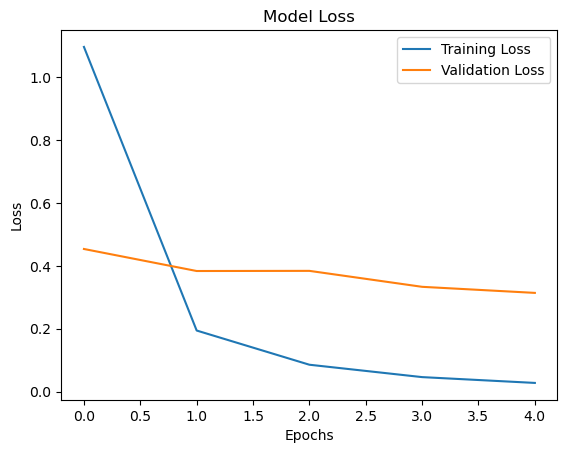

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


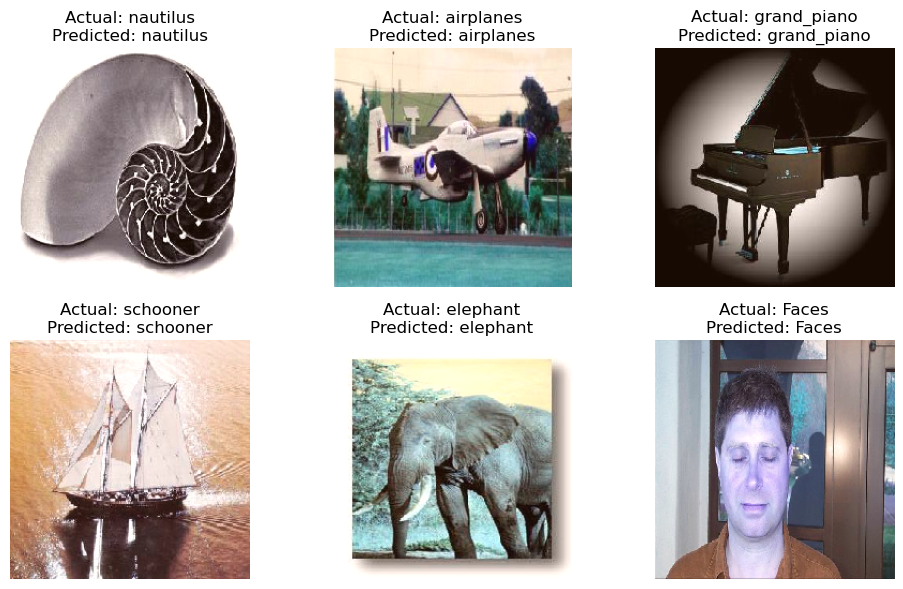

In [2]:

# Assignment 5A: Transfer Learning using ResNet50

# 1. Import libraries
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D

# 2. Load dataset
DATA_DIR = "caltech-101"

datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    validation_split=0.2
)

train_data = datagen.flow_from_directory(
    DATA_DIR,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    subset='training'
)

val_data = datagen.flow_from_directory(
    DATA_DIR,
    target_size=(224, 224),
    batch_size=32,
    class_mode='categorical',
    subset='validation'
)

# 3. Load pre-trained ResNet50
base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

# 4. Freeze pre-trained layers
base_model.trainable = False

# 5. Add classification layers
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(128, activation='relu'),
    Dense(train_data.num_classes, activation='softmax')
])

# 6. Compile model
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# 7. Train model
history = model.fit(
    train_data,
    epochs=5,
    validation_data=val_data
)

# 8. Evaluate model
loss, accuracy = model.evaluate(val_data)

print("Validation Loss:", loss)
print("Validation Accuracy:", accuracy)

# 9. Plot accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# 10. Plot loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

# 11. Visualize predictions
images, labels = next(val_data)

predictions = model.predict(images)

class_names = list(val_data.class_indices.keys())

plt.figure(figsize=(10, 6))

for i in range(6):
    plt.subplot(2, 3, i+1)

    actual = np.argmax(labels[i])
    predicted = np.argmax(predictions[i])

    plt.imshow(np.clip(images[i] / 255 + 0.5, 0, 1))

    plt.title(
        "Actual: " + class_names[actual] +
        "\nPredicted: " + class_names[predicted]
    )

    plt.axis('off')

plt.tight_layout()
plt.show()
